# 04 - Model Evaluation

This notebook evaluates the YOLO11n model trained in notebook 03. The first objective is to measure how accurately the model counts plastic bottles in the UCWD validation images.

For each image, we compare the number of annotated bottles with the number of predicted bottles. We start with an image size of 640 pixels and a confidence threshold of 0.25.

In [1]:
from pathlib import Path

import pandas as pd
from ultralytics import YOLO

repo = Path.home() / "Documents" / "GitHub" / "plastic-waste-detection"
validation = repo / "data" / "raw" / "ucwd" / "UCWD.yolo" / "valid"

image_dir = validation / "images"
label_dir = validation / "labels"
run_dir = repo / "results" / "training" / "yolo11n_baseline_640"

model = YOLO(str(run_dir / "weights" / "best.pt"))

bottle_id = next(
    class_id for class_id, name in model.names.items()
    if name == "Plastic bottle"
)
confidence_threshold = 0.25

print("Plastic bottle class ID:", bottle_id)

Plastic bottle class ID: 4


## 1. Compare annotated and predicted counts on one image

We start with `batch_s02_img_98`, the image with a circle on the ground. We count the annotations and predictions for the `Plastic bottle` class.

The signed counting error is the predicted count minus the annotated count. A positive value indicates overcounting, and a negative value indicates undercounting.

In [2]:
def count_bottles(result):
    image_path = Path(result.path)
    label_path = label_dir / f"{image_path.stem}.txt"

    # Background images can have no annotation file.
    label_lines = []
    if label_path.exists():
        label_lines = label_path.read_text(encoding="utf-8").splitlines()

    annotated_count = sum(
        int(line.split()[0]) == bottle_id
        for line in label_lines
        if line.strip()
    )

    predicted_count = int((result.boxes.cls == bottle_id).sum().item())

    return {
        "image": image_path.name,
        "annotated_bottles": annotated_count,
        "predicted_bottles": predicted_count,
        "count_error": predicted_count - annotated_count,
    }


example_image = next(image_dir.glob("batch_s02_img_98_jpg*.jpg"))

example_result = model.predict(
    source=str(example_image),
    imgsz=640,
    conf=confidence_threshold,
    device=0,
    verbose=False,
)[0]

pd.DataFrame([count_bottles(example_result)])

,image,annotated_bottles,predicted_bottles,count_error
0,batch_s02_img_98_jpg.rf.70a4e92d3f370efedb5a78...,1,2,1


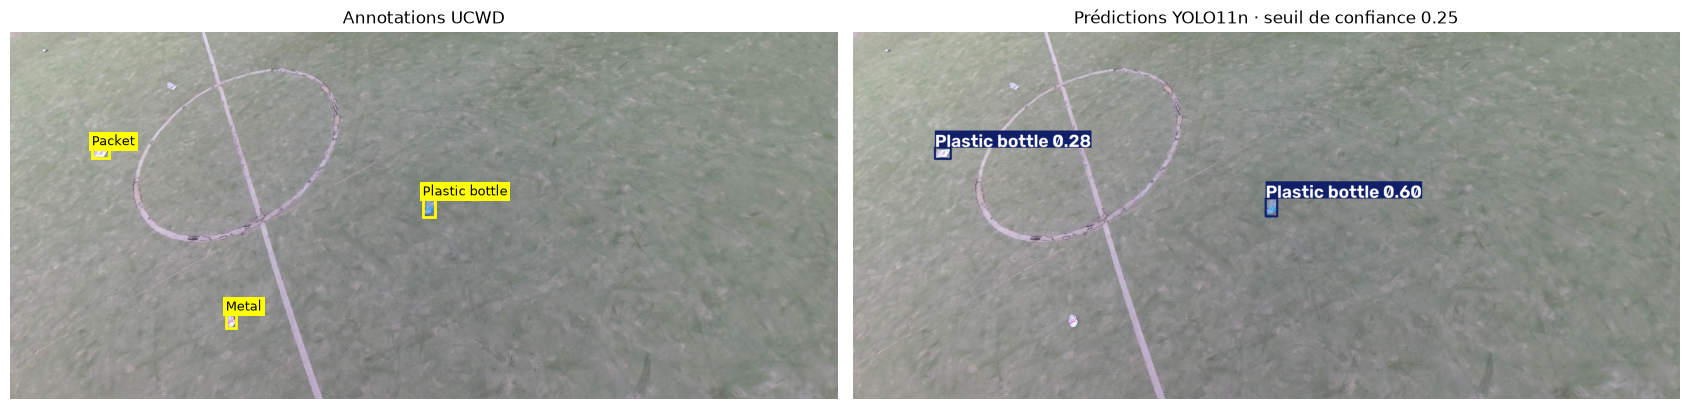

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Réutiliser l'image et la prédiction de la cellule 4.
image_rgb = example_result.orig_img[:, :, ::-1]
height, width = image_rgb.shape[:2]

label_path = label_dir / f"{example_image.stem}.txt"
label_lines = label_path.read_text(encoding="utf-8").splitlines()

fig, (ax_annotations, ax_predictions) = plt.subplots(1, 2, figsize=(17, 8))

ax_annotations.imshow(image_rgb)
ax_annotations.set_title("Annotations UCWD")

for line in label_lines:
    if not line.strip():
        continue

    class_id, x_center, y_center, box_width, box_height = map(float, line.split())

    # Passer des coordonnées relatives au coin supérieur gauche en pixels.
    x = (x_center - box_width / 2) * width
    y = (y_center - box_height / 2) * height

    ax_annotations.add_patch(
        Rectangle(
            (x, y),
            box_width * width,
            box_height * height,
            fill=False,
            edgecolor="yellow",
            linewidth=2,
        )
    )
    ax_annotations.text(
        x, y, model.names[int(class_id)],
        color="black",
        fontsize=9,
        va="bottom",
        bbox={"facecolor": "yellow", "edgecolor": "none", "pad": 2},
    )

ax_predictions.imshow(example_result.plot()[:, :, ::-1])
ax_predictions.set_title(f"Prédictions YOLO11n · seuil de confiance {confidence_threshold}")

ax_annotations.axis("off")
ax_predictions.axis("off")
plt.tight_layout()
plt.show()

## 2. Evaluate counting errors on the validation set

We apply the same comparison to all 500 validation images, including images with no annotated bottles.

Mean signed error measures the overall tendency to overcount or undercount. Mean absolute error measures the average size of the counting error per image.

In [4]:
validation_results = model.predict(
    source=str(image_dir),
    imgsz=640,
    conf=confidence_threshold,
    device=0,
    stream=True,
    verbose=False,
)

evaluation = pd.DataFrame(
    count_bottles(result) for result in validation_results
)

errors = evaluation["count_error"]

print(f"Images evaluated: {len(evaluation)}")
print(f"Annotated bottles: {evaluation['annotated_bottles'].sum()}")
print(f"Predicted bottles: {evaluation['predicted_bottles'].sum()}")
print(f"Mean signed error: {errors.mean():+.2f} bottles/image")
print(f"Mean absolute error: {errors.abs().mean():.2f} bottles/image")

evaluation.head()

Images evaluated: 500
Annotated bottles: 1340
Predicted bottles: 1029
Mean signed error: -0.62 bottles/image
Mean absolute error: 0.99 bottles/image


,image,annotated_bottles,predicted_bottles,count_error
0,BATCH_d06_img_1390_jpg.rf.084429c0feb3a04e9dfc...,1,0,-1
1,BATCH_d06_img_1500_jpg.rf.72e195a48733f3625fb4...,2,0,-2
2,BATCH_d06_img_1580_jpg.rf.d4ca04cd837da64744d2...,0,0,0
3,BATCH_d06_img_1790_jpg.rf.4d13e98ae350a1029c49...,0,0,0
4,BATCH_d06_img_200_jpg.rf.fe24409fd129bfb0e051f...,2,1,-1


## 3. Compare confidence thresholds

At a confidence threshold of 0.25, YOLO11n predicted 1,029 plastic bottles
across the 500 validation images, compared with 1,340 annotations.
The mean signed error was −0.62 bottles per image and the mean absolute
error was 0.99 bottles per image.

We compare three confidence thresholds on the validation set to see which
one gives the lowest mean absolute counting error.

In [5]:
threshold_results = []

for threshold in [0.15, 0.25, 0.35]:
    if threshold == 0.25:
        # Réutiliser le tableau déjà calculé.
        counts = evaluation
    else:
        results = model.predict(
            source=str(image_dir),
            imgsz=640,
            conf=threshold,
            device=0,
            stream=True,
            verbose=False,
        )
        counts = pd.DataFrame(count_bottles(result) for result in results)

    errors = counts["count_error"]
    threshold_results.append({
        "threshold": threshold,
        "predicted_bottles": counts["predicted_bottles"].sum(),
        "mean_signed_error": errors.mean(),
        "mean_absolute_error": errors.abs().mean(),
    })

threshold_comparison = pd.DataFrame(threshold_results)
threshold_comparison.sort_values("mean_absolute_error").round(3)

,threshold,predicted_bottles,mean_signed_error,mean_absolute_error
0,0.15,1337,-0.006,0.886
1,0.25,1029,-0.622,0.986
2,0.35,847,-0.986,1.170


### Confidence threshold results for plastic bottles

Among the three thresholds tested on the validation set, 0.15 gave the
lowest mean absolute counting error for plastic bottles (0.886 bottles
per image). The model predicted 1,337 bottles compared with 1,340
annotations. The small difference in total counts can hide overcounts
and undercounts on individual images.

## 4. Evaluate counting errors across plastic classes

We compare confidence thresholds of 0.15 and 0.25 on the 500 validation
images. For each image, we count annotated and predicted objects for
plastic bottles, bags, containers, and fragments.

We report the signed and absolute counting errors for each class and
for the combined plastic count per image. The combined count measures
whether the model gets the total right, even if it confuses two plastic
categories.

In [6]:
from collections import Counter

plastic_names = [
    "Plastic bottle",
    "Plastic bag",
    "Plastic container",
    "Plastic fragment",
]
plastic_ids = {
    name: class_id
    for class_id, name in model.names.items()
    if name in plastic_names
}

rows = []

for threshold in [0.15, 0.25]:
    results = model.predict(
        source=str(image_dir),
        imgsz=640,
        conf=threshold,
        device=0,
        stream=True,
        verbose=False,
    )

    for result in results:
        image_path = Path(result.path)
        label_path = label_dir / f"{image_path.stem}.txt"

        lines = []
        if label_path.exists():
            lines = label_path.read_text(encoding="utf-8").splitlines()

        annotated = Counter(
            int(line.split()[0]) for line in lines if line.strip()
        )
        predicted = Counter(result.boxes.cls.int().tolist())

        for name, class_id in plastic_ids.items():
            rows.append({
                "threshold": threshold,
                "image": image_path.name,
                "category": name,
                "annotated": annotated[class_id],
                "predicted": predicted[class_id],
            })

plastic_counts = pd.DataFrame(rows)

# Additionner les quatre classes sur chaque photo avant de calculer l'erreur.
total_counts = (
    plastic_counts.groupby(["threshold", "image"], as_index=False)
    [["annotated", "predicted"]]
    .sum()
)
total_counts["category"] = "All four plastic classes"

counts = pd.concat([plastic_counts, total_counts], ignore_index=True)
counts["signed_error"] = counts["predicted"] - counts["annotated"]
counts["absolute_error"] = counts["signed_error"].abs()

plastic_summary = (
    counts.groupby(["category", "threshold"], as_index=False)
    .agg(
        images=("image", "size"),
        annotated=("annotated", "sum"),
        predicted=("predicted", "sum"),
        bias=("signed_error", "mean"),
        mae=("absolute_error", "mean"),
    )
)

plastic_summary.round(3)

,category,threshold,images,annotated,predicted,bias,mae
0,All four plastic classes,0.15,500,2038,2008,-0.060,1.256
1,All four plastic classes,0.25,500,2038,1607,-0.862,1.402
2,Plastic bag,0.15,500,73,80,0.014,0.118
3,Plastic bag,0.25,500,73,64,-0.018,0.098
4,Plastic bottle,0.15,500,1340,1337,-0.006,0.886
5,Plastic bottle,0.25,500,1340,1029,-0.622,0.986
6,Plastic container,0.15,500,184,158,-0.052,0.184
7,Plastic container,0.25,500,184,136,-0.096,0.192
8,Plastic fragment,0.15,500,441,433,-0.016,0.392
9,Plastic fragment,0.25,500,441,378,-0.126,0.342


## 5. Evaluate plastic counts on the test set

We selected a confidence threshold of 0.15 on the validation set.
For the combined count of the four plastic classes, it reduced the
mean absolute error from 1.402 to 1.256 objects per image.

We now evaluate the same model on the UCWD test images at a fixed
threshold of 0.15 and an image size of 640 pixels. The original UCWD
splits share video sequences, so these results describe performance
on the UCWD test split. Generalization to entirely new videos remains
to be measured.

In [7]:
test_dir = validation.parent / "test"
test_threshold = 0.15

test_predictions = model.predict(
    source=str(test_dir / "images"),
    imgsz=640,
    conf=test_threshold,
    device=0,
    stream=True,
    verbose=False,
)

test_rows = []

for result in test_predictions:
    image_path = Path(result.path)
    label_path = test_dir / "labels" / f"{image_path.stem}.txt"

    lines = []
    if label_path.exists():
        lines = label_path.read_text(encoding="utf-8").splitlines()

    annotated = Counter(int(line.split()[0]) for line in lines if line.strip())
    predicted = Counter(result.boxes.cls.int().tolist())

    for name, class_id in plastic_ids.items():
        test_rows.append({
            "image": image_path.name,
            "category": name,
            "annotated": annotated[class_id],
            "predicted": predicted[class_id],
        })

test_counts = pd.DataFrame(test_rows)

test_totals = (
    test_counts.groupby("image", as_index=False)[["annotated", "predicted"]]
    .sum()
)
test_totals["category"] = "All four plastic classes"

test_counts = pd.concat([test_counts, test_totals], ignore_index=True)
test_counts["signed_error"] = test_counts["predicted"] - test_counts["annotated"]
test_counts["absolute_error"] = test_counts["signed_error"].abs()

test_summary = test_counts.groupby("category").agg(
    images=("image", "size"),
    annotated=("annotated", "sum"),
    predicted=("predicted", "sum"),
    bias=("signed_error", "mean"),
    mae=("absolute_error", "mean"),
)

test_summary.round(3)

,images,annotated,predicted,bias,mae
category,,,,,
All four plastic classes,500,2235,2059,-0.352,1.380
Plastic bag,500,116,98,-0.036,0.136
Plastic bottle,500,1434,1330,-0.208,0.988
Plastic container,500,221,189,-0.064,0.200
Plastic fragment,500,464,442,-0.044,0.384


### Test set results

At a fixed confidence threshold of 0.15, YOLO11n predicted 2,059
plastic objects across 500 UCWD test images, compared with 2,235
annotations. The mean absolute counting error was 1.380 objects per
image, compared with 1.256 on the validation set.

The model had a net undercount of 176 objects, or 7.9% of the
annotated total. Plastic bottles accounted for the largest share of
this gap. Because the original UCWD splits share video sequences,
these results describe performance on the UCWD test split.

In [8]:
worst_test_images = (
    test_counts.loc[test_counts["category"] == "All four plastic classes"]
    .nlargest(5, "absolute_error")
    [["image", "annotated", "predicted", "signed_error"]]
)

worst_test_images

,image,annotated,predicted,signed_error
2167,DJI_0037_JPG.rf.e886756552040d0c2e81b6603d3d69...,35,10,-25
2154,DJI_0019_JPG.rf.230449cedac48ed8429d1e3cf46300...,26,8,-18
2162,DJI_0026_JPG.rf.a552df84aa953023436f178875932d...,33,17,-16
2203,DJI_0121_JPG.rf.efb577559b1b9576d0f926a62636e4...,33,18,-15
2192,DJI_0104_JPG.rf.cc620db9432973b22744a61db5af96...,14,28,14


## 6. Inspect large counting errors

We inspect two test images with large counting errors: `DJI_0037`
for undercounting and `DJI_0104` for overcounting. We compare the
UCWD annotations and YOLO11n predictions for the four plastic classes
at the fixed confidence threshold of 0.15.

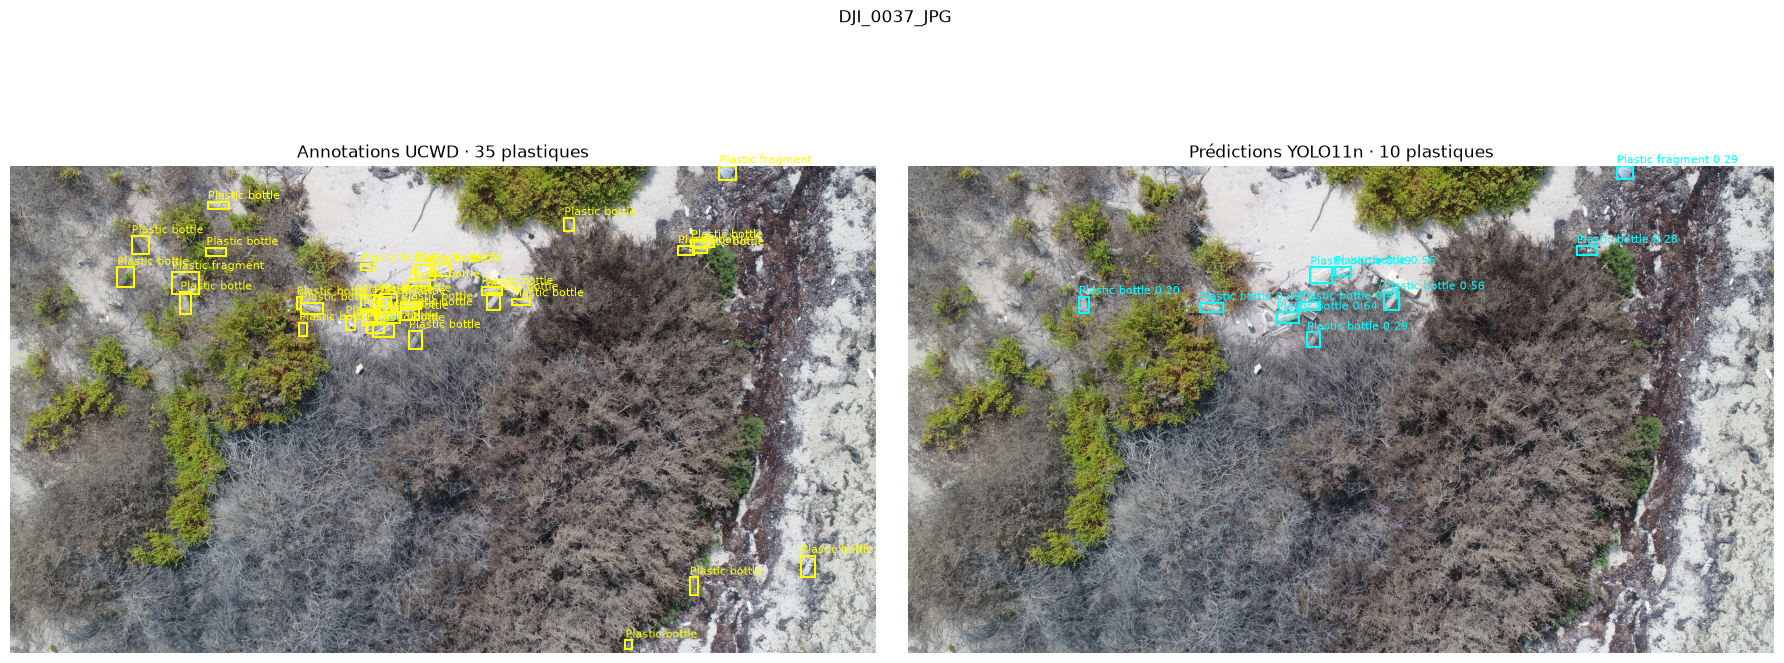

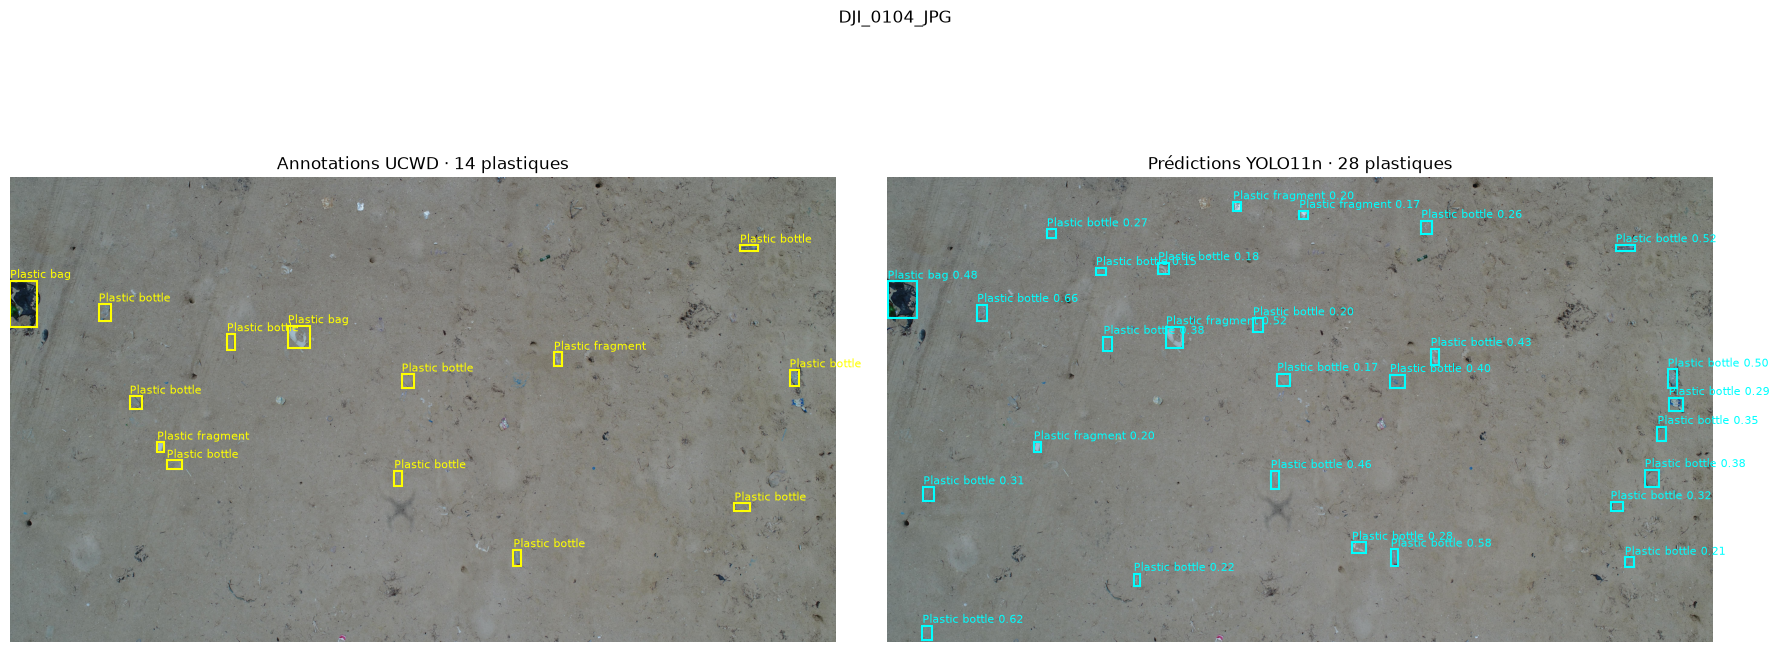

In [ ]:
# Prendre le plus gros sous-comptage et le plus gros surcomptage du tableau
selected = worst_test_images.sort_values("signed_error").iloc[[0, -1]]
plastic_class_ids = set(plastic_ids.values())


def draw_box(ax, x, y, w, h, label, color):
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1.5))
    ax.text(x, y, label, color=color, fontsize=8, va="bottom")


for row in selected.itertuples():
    image_path = test_dir / "images" / row.image
    label_path = test_dir / "labels" / f"{image_path.stem}.txt"

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=test_threshold,
        device=0,
        verbose=False,
    )[0]

    image_rgb = result.orig_img[:, :, ::-1]
    height, width = image_rgb.shape[:2]
    fig, (ax_ref, ax_pred) = plt.subplots(1, 2, figsize=(18, 8))

    for ax in (ax_ref, ax_pred):
        ax.imshow(image_rgb)
        ax.axis("off")

    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        class_id, cx, cy, w, h = map(float, line.split())
        if int(class_id) in plastic_class_ids:
            x = (cx - w / 2) * width
            y = (cy - h / 2) * height
            draw_box(ax_ref, x, y, w * width, h * height, model.names[int(class_id)], "yellow")

    for coords, class_id, score in zip(
        result.boxes.xyxy.tolist(),
        result.boxes.cls.int().tolist(),
        result.boxes.conf.tolist(),
    ):
        if class_id in plastic_class_ids:
            x1, y1, x2, y2 = coords
            label = f"{model.names[class_id]} {score:.2f}"
            draw_box(ax_pred, x1, y1, x2 - x1, y2 - y1, label, "cyan")

    ax_ref.set_title(f"Annotations UCWD · {row.annotated} plastiques")
    ax_pred.set_title(f"Prédictions YOLO11n · {row.predicted} plastiques")
    fig.suptitle(row.image.split(".rf.")[0])
    plt.tight_layout()
    plt.show()

On `DJI_0037`, the model undercounted plastic objects by 25.
Several annotated bottles in the lower-right area had no nearby
prediction, and only part of the dense central cluster was detected.

On `DJI_0104`, the model overcounted by 14. Several predicted
bottles had no matching visible annotation. These two examples
illustrate how missed detections and extra predictions can affect
the final count.

In [10]:
test_detection = model.val(
    data=str(repo / "configs" / "ucwd.yaml"),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    verbose=True,
)

print(f"Test mAP50:    {test_detection.box.map50:.3f}")
print(f"Test mAP50-95: {test_detection.box.map:.3f}")

Ultralytics 8.4.216  Python-3.11.7 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 4GB Laptop GPU, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 648.6±559.6 MB/s, size: 934.3 KB)
val: Scanning C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\raw\ucwd\UCWD.yolo\test\labels... 500 images, 16 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 906.9it/s 0.6s0.0s
val: New cache created: C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\raw\ucwd\UCWD.yolo\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 1.6it/s 1:170.9ss
                   all        500       3319      0.844      0.651      0.748      0.458
                 Glass        131        319      0.801      0.619      0.685      0.403
                 Metal        152        496      0.852       0.81      0.857      0.449
       

## 7. Conclusion

On the 500 UCWD test images, YOLO11n achieved a mAP50 of 0.748
and a mAP50–95 of 0.458 across all seven classes. Among the four
plastic classes, bottles had the lowest mAP50–95 (0.360).

At the confidence threshold of 0.15 selected on the validation set,
the model predicted 2,059 plastic objects compared with 2,235
annotations. The mean absolute counting error was 1.38 objects per
image, with a net undercount of 176 objects (7.9%).

The original UCWD splits share video sequences. These results describe
performance on the UCWD test split, and generalization to entirely new
videos remains to be evaluated.